In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

htb_green = "#9fef00"
node_black = "#141d2b"
hacker_grey = "#a4b1cd"
white = "#ffffff"
azure = "#0086ff"
nugget_yellow = "#ffaf00"
malware_red = "#ff3e3e"
vivid_purple = "#9f00ff"
aquamarine = "#2ee7b6"

# Configure plot styles
plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update(
    {
        "figure.facecolor": node_black,
        "axes.facecolor": node_black,
        "axes.edgecolor": hacker_grey,
        "axes.labelcolor": white,
        "text.color": white,
        "xtick.color": hacker_grey,
        "ytick.color": hacker_grey,
        "grid.color": hacker_grey,
        "grid.alpha": 0.1,
        "legend.facecolor": node_black,
        "legend.edgecolor": hacker_grey,
        "legend.frameon": True,
        "legend.framealpha": 1.0,
        "legend.labelcolor": white,
    }
)

# Seed for reproducibility
SEED = 1337
np.random.seed(SEED)

print("Setup complete. Libraries imported and styles configured.")

# Generate synthetic data
n_samples = 1000
centers = [(0, 5), (5, 0)]  # Define centers for two distinct blobs
X, y = make_blobs(
    n_samples=n_samples,
    centers=centers,
    n_features=2,
    cluster_std=1.25,
    random_state=SEED,
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED
)

print(f"Generated {n_samples} samples.")
print(f"Training set size: {X_train.shape[0]} samples.")
print(f"Testing set size: {X_test.shape[0]} samples.")
print(f"Number of features: {X_train.shape[1]}")
print(f"Classes: {np.unique(y)}")

Setup complete. Libraries imported and styles configured.
Generated 1000 samples.
Training set size: 700 samples.
Testing set size: 300 samples.
Number of features: 2
Classes: [0 1]


In [3]:
def plot_poisoned_data(
    X,
    y_original,
    y_poisoned,
    flipped_indices,
    title="Poisoned Data Visualization",
    target_class_info=None,
):
    """
    Plots a 2D dataset, highlighting points whose labels were flipped.

    Parameters:
    - X (np.ndarray): Feature data (n_samples, 2).
    - y_original (np.ndarray): The original labels before flipping (used for context if needed, currently unused in logic but good practice).
    - y_poisoned (np.ndarray): Labels after flipping.
    - flipped_indices (np.ndarray): Indices of the samples that were flipped.
    - title (str): The title for the plot.
    - target_class_info (int, optional): The class label of the points that were targeted for flipping. Defaults to None.
    """
    plt.figure(figsize=(12, 7))

    # Identify non-flipped points
    mask_not_flipped = np.ones(len(y_poisoned), dtype=bool)
    mask_not_flipped[flipped_indices] = False

    # Plot non-flipped points (color by their poisoned label, which is same as original)
    plt.scatter(
        X[mask_not_flipped, 0],
        X[mask_not_flipped, 1],
        c=y_poisoned[mask_not_flipped],
        cmap=plt.cm.colors.ListedColormap([azure, nugget_yellow]),
        edgecolors=node_black,
        s=50,
        alpha=0.6,
        label="Unchanged Label",  # Keep this generic
    )

    # Determine the label for flipped points in the legend
    if target_class_info is not None:
        flipped_legend_label = f"Flipped (Orig Class {target_class_info})"
        # You could potentially use target_class_info to adjust facecolor if needed,
        # but current logic colors by the new label which is often clearer.
    else:
        flipped_legend_label = "Flipped Label"

    # Plot flipped points with a distinct marker and outline
    if len(flipped_indices) > 0:
        # Color flipped points according to their new (poisoned) label
        plt.scatter(
            X[flipped_indices, 0],
            X[flipped_indices, 1],
            c=y_poisoned[flipped_indices],  # Color by the new label
            cmap=plt.cm.colors.ListedColormap([azure, nugget_yellow]),
            edgecolors=malware_red,  # Highlight edge in red
            linewidths=1.5,
            marker="X",  # Use 'X' marker
            s=100,
            alpha=0.9,
            label=flipped_legend_label,  # Use the determined label
        )

    plt.title(title, fontsize=16, color=htb_green)
    plt.xlabel("Feature 1", fontsize=12)
    plt.ylabel("Feature 2", fontsize=12)

    # Create legend
    handles = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label="Class 0 Point (Azure)",
            markersize=10,
            markerfacecolor=azure,
            linestyle="None",
        ),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label="Class 1 Point (Yellow)",
            markersize=10,
            markerfacecolor=nugget_yellow,
            linestyle="None",
        ),
        # Add the flipped legend entry using the label
        plt.Line2D(
            [0],
            [0],
            marker="X",
            color="w",
            label=flipped_legend_label,
            markersize=12,
            markeredgecolor=malware_red,
            markerfacecolor=hacker_grey,
            linestyle="None",
        ),
    ]
    plt.legend(handles=handles, title="Data Points")
    plt.grid(True, color=hacker_grey, linestyle="--", linewidth=0.5, alpha=0.3)
    plt.show()


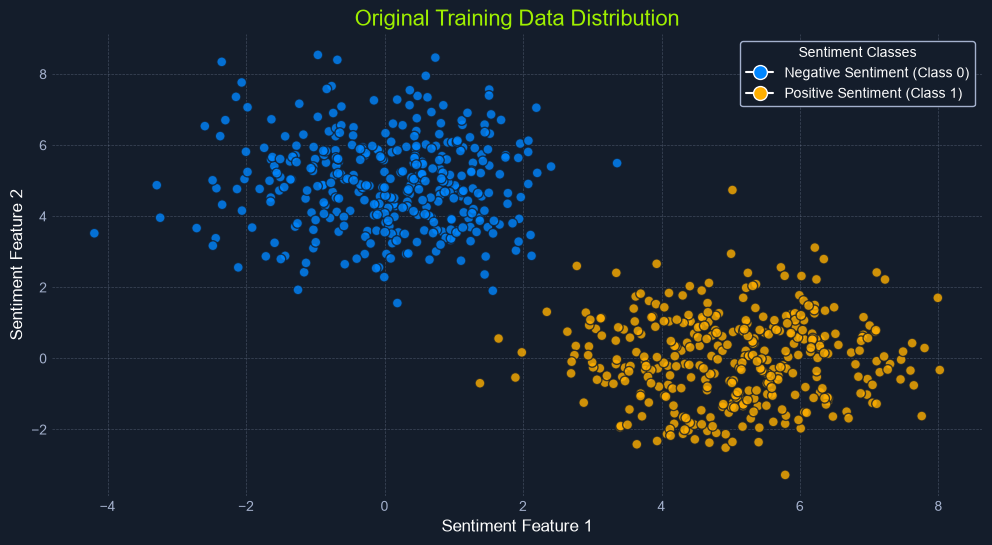

In [4]:
def plot_data(X, y, title="Dataset Visualization"):
    """
    Plots the 2D dataset with class-specific colors.

    Parameters:
    - X (np.ndarray): Feature data (n_samples, 2).
    - y (np.ndarray): Labels (n_samples,).
    - title (str): The title for the plot.
    """
    plt.figure(figsize=(12, 6))
    scatter = plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        cmap=plt.cm.colors.ListedColormap([azure, nugget_yellow]),
        edgecolors=node_black,
        s=50,
        alpha=0.8,
    )
    plt.title(title, fontsize=16, color=htb_green)
    plt.xlabel("Sentiment Feature 1", fontsize=12)
    plt.ylabel("Sentiment Feature 2", fontsize=12)
    # Create a legend
    handles = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label="Negative Sentiment (Class 0)", 
            markersize=10,
            markerfacecolor=azure,
        ),
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            label="Positive Sentiment (Class 1)",
            markersize=10,
            markerfacecolor=nugget_yellow,
        ),
    ]
    plt.legend(handles=handles, title="Sentiment Classes")
    plt.grid(True, color=hacker_grey, linestyle="--", linewidth=0.5, alpha=0.3)
    plt.show()


# Plot the data
plot_data(X_train, y_train, title="Original Training Data Distribution")


In [5]:
def targeted_flip_labels(y, poison_percentange, target_class, new_class, seed=1337):

    if not 0 <= poison_percentange <= 1:
        raise ValueError("poison_percentange must be between 0 and 1")
    if target_class == new_class:
        raise ValueError("target_class and new_class must be different")
    unique_labels = np.unique(y)
    if target_class not in unique_labels:
        raise ValueError("target_class must be one of the existing labels")
    if new_class not in unique_labels:
        raise ValueError("new_class must be one of the existing labels")

    target_indices = np.where(y == target_class)[0]
    n_target_samples = len(target_indices)

    if n_target_samples == 0:
        print(f"No samples found for the target_class{target_class}. No labels flipped")
        return y.copy(), np.array([], dtype=int)
    
    n_to_flip = int(n_target_samples * poison_percentange)

    if n_to_flip == 0:
        print(f"Warning: Poison percentage ({poison_percentange * 100:.1f}%) is too low" f"to flip any labels in the target class ({n_target_samples})")
        return y.copy(), np.array([], dtype=int)

    rng_instance = np.random.default_rng(seed)

    indices_within_target_set_to_flip  = rng_instance.choice(
        n_target_samples, size=n_to_flip, replace=False
    )
    flipped_indeces = target_indices[indices_within_target_set_to_flip]

    y_poisoned = y.copy()

    y_poisoned[flipped_indeces] = new_class

    print(f"Targetd Class {target_class} flipped to {new_class}.")
    print(f"Identified {n_target_samples} samples of Class {target_class}.")
    print(f"Attempting to flip {poison_percentange * 100:.1f}%({n_to_flip} samples) of these.")
    print(f"Successfully flipped {len(flipped_indeces)} labels.")

    return y_poisoned, flipped_indeces



Targetd Class 1 flipped to 0.
Identified 353 samples of Class 1.
Attempting to flip 40.0%(141 samples) of these.
Successfully flipped 141 labels.

--- Visualizing Targeted Poisoned Data ---


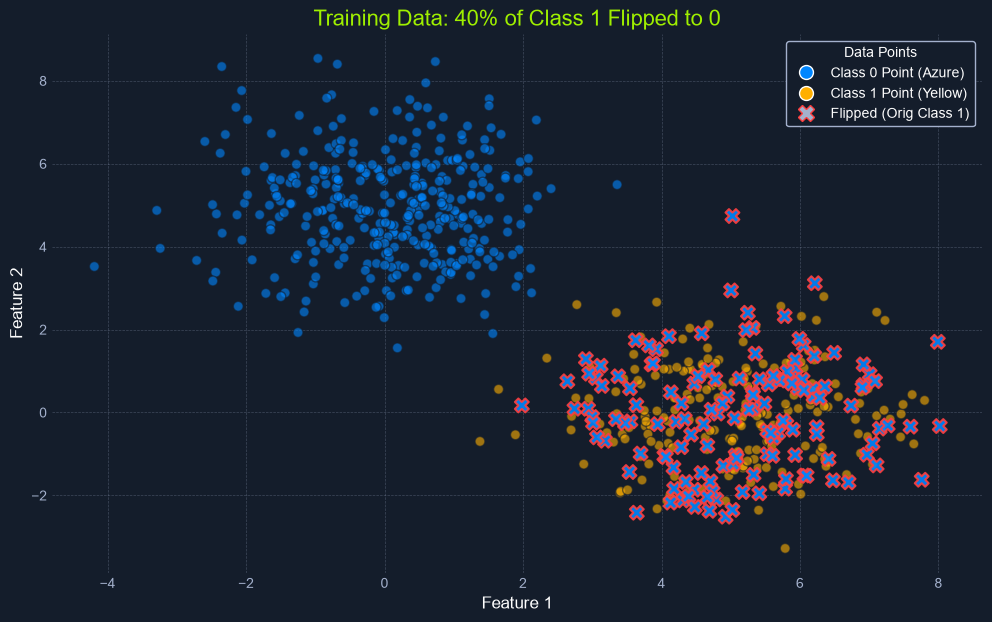

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",1337
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [6]:
# Generate synthetic data
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import numpy as np

poison_percentage_targeted = 0.4
target_class_to_flip = 1
new_label_for_flipped = 0

y_train_targeted_poisoned, targeted_flipped_indices = targeted_flip_labels(
    y_train,
    poison_percentage_targeted,
    target_class_to_flip,
    new_label_for_flipped
)

print("\n--- Visualizing Targeted Poisoned Data ---")
# Plot the result of the targeted flip
plot_poisoned_data(
    X_train,
    y_train,  # Pass original y
    y_train_targeted_poisoned,
    targeted_flipped_indices,
    title=f"Training Data: {poison_percentage_targeted * 100:.0f}% of Class {target_class_to_flip} Flipped to {new_label_for_flipped}",
    target_class_info=target_class_to_flip,
)

targeted_poisoned_model = LogisticRegression(random_state=SEED)
targeted_poisoned_model.fit(X_train, y_train_targeted_poisoned)

Baseline Model Accuracy: 0.9933

 --- Evaluating Targeted Poisoned Model ---
Accuracy on clean dataset: 0.8100
Baseline accuracy was: 0.9933

Classification Report on Clean Test Set:
              precision    recall  f1-score   support

     Class 0       0.73      1.00      0.84       153
     Class 1       1.00      0.61      0.76       147

    accuracy                           0.81       300
   macro avg       0.86      0.81      0.80       300
weighted avg       0.86      0.81      0.80       300



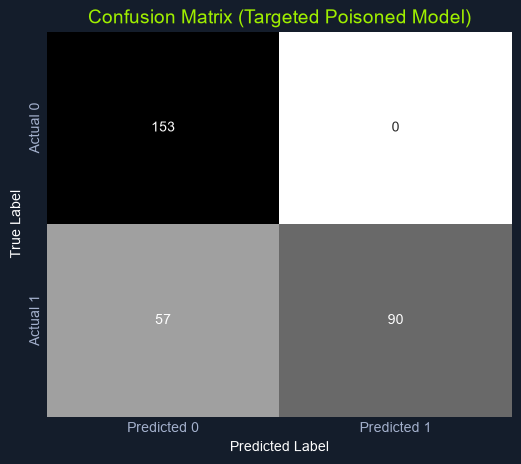

In [7]:
#Predict on the clean dataset
y_pred_targeted = targeted_poisoned_model.predict(X_test)

#Baseline
baseline_model = LogisticRegression(random_state=SEED)
baseline_model.fit(X_train, y_train)

# Predict on the test set
y_pred_baseline = baseline_model.predict(X_test)

# Calculate baseline accuracy
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
print(f"Baseline Model Accuracy: {baseline_accuracy:.4f}")

#Calculate the accuracy on the clean dataset
targeted_accuracy = accuracy_score(y_test, y_pred_targeted)
print(f"\n --- Evaluating Targeted Poisoned Model ---")
print(f"Accuracy on clean dataset: {targeted_accuracy:.4f}")
print(f"Baseline accuracy was: {baseline_accuracy:.4f}")

#Display the classification report
print("\nClassification Report on Clean Test Set:")
print(classification_report(y_test, y_pred_targeted, target_names=["Class 0", "Class 1"]))

#Plot the Confusion matrix
cm_targeted = confusion_matrix(y_test, y_pred_targeted)
plt.figure(figsize=(6,5))
sns.heatmap(cm_targeted, annot=True, fmt="d", cmap="binary", xticklabels=["Predicted 0", "Predicted 1"], yticklabels=["Actual 0", "Actual 1"], cbar=False,)

plt.xlabel("Predicted Label", color=white)
plt.ylabel("True Label", color=white)
plt.title("Confusion Matrix (Targeted Poisoned Model)", fontsize=14, color=htb_green)
plt.xticks(color=hacker_grey)
plt.yticks(color=hacker_grey)
plt.show()


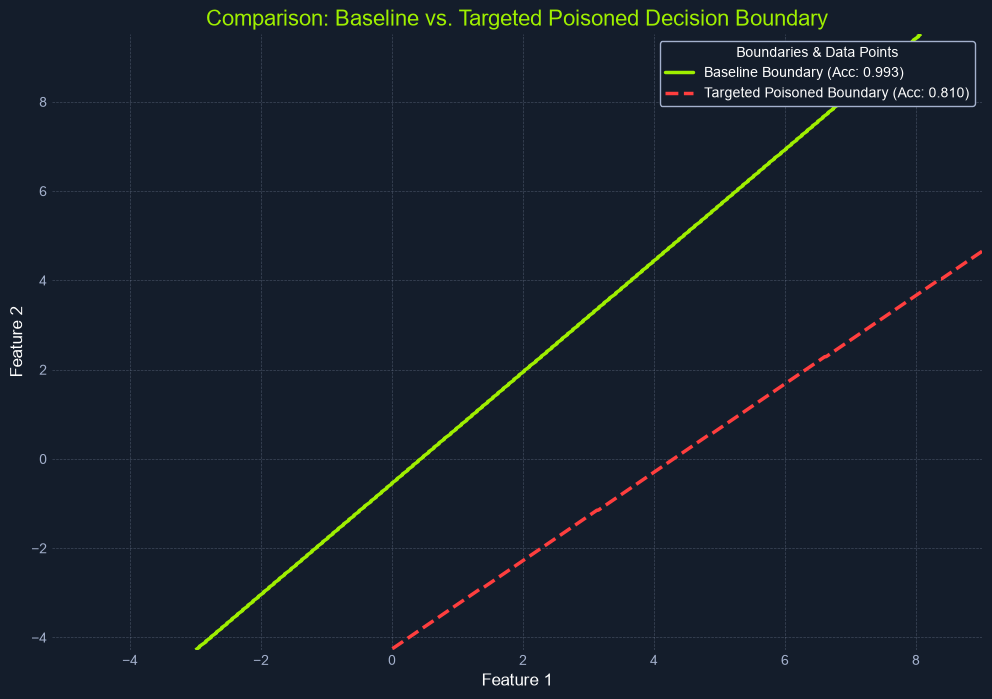

In [8]:
plt.figure(figsize=(12, 8))

h = 0.02  # Step size in the mesh
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
mesh_points = np.c_[xx.ravel(), yy.ravel()]
Z_baseline = baseline_model.predict(mesh_points).reshape(xx.shape)
plt.contour(
    xx,
    yy,
    Z_baseline,
    levels=[0.5],
    colors=[htb_green],
    linestyles=["solid"],
    linewidths=[2.5],
)

# Plot Targeted Poisoned Decision Boundary (Dashed Red)
Z_targeted = targeted_poisoned_model.predict(mesh_points).reshape(xx.shape)
plt.contour(
    xx,
    yy,
    Z_targeted,
    levels=[0.5],
    colors=[malware_red],
    linestyles=["dashed"],
    linewidths=[2.5],
)

plt.title(
    "Comparison: Baseline vs. Targeted Poisoned Decision Boundary",
    fontsize=16,
    color=htb_green,
)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)

# Create legend combining data points and boundaries
handles = [
    plt.Line2D(
        [0],
        [0],
        color=htb_green,
        lw=2.5,
        linestyle="solid",
        label=f"Baseline Boundary (Acc: {baseline_accuracy:.3f})",
    ),
    plt.Line2D(
        [0],
        [0],
        color=malware_red,
        lw=2.5,
        linestyle="dashed",
        label=f"Targeted Poisoned Boundary (Acc: {targeted_accuracy:.3f})",
    ),
]

plt.legend(handles=handles, title="Boundaries & Data Points")
plt.grid(True, color=hacker_grey, linestyle="--", linewidth=0.5, alpha=0.3)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.show()

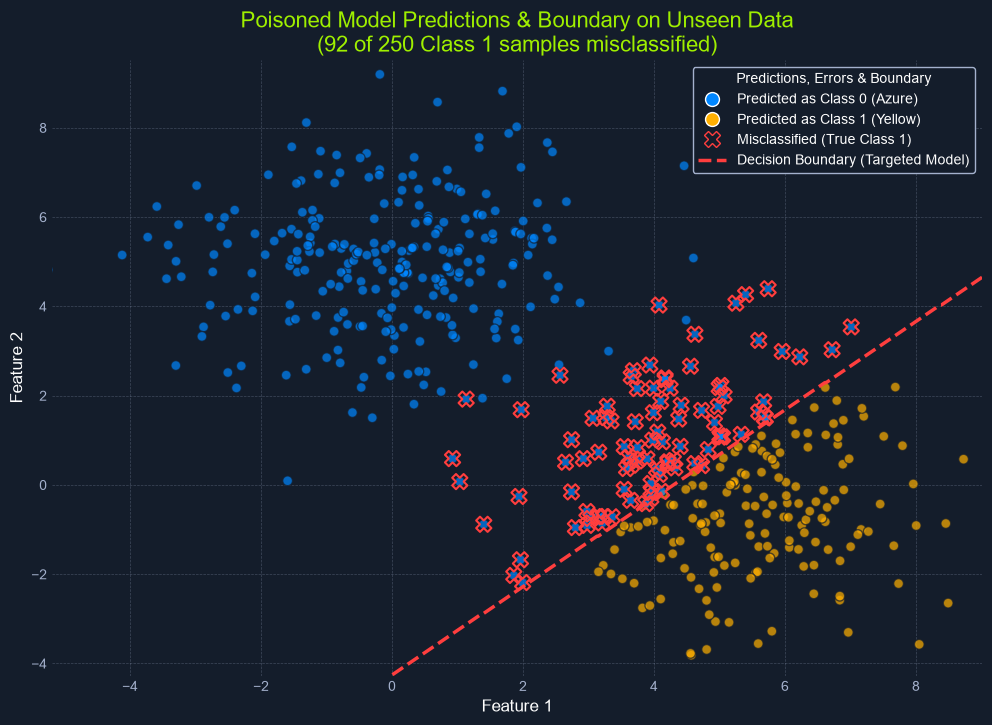

In [9]:
# Define parameters for unseen data generation
n_unseen_samples = 500
unseen_seed = SEED + 1337

# Generate unseen data
X_unseen, y_unseen = make_blobs(
    n_samples=n_unseen_samples,
    centers=centers,
    n_features=2,
    cluster_std=1.50,
    random_state=unseen_seed,
)

# Predict labels for the unseen data using the targeted poisoned model
y_pred_unseen_poisoned = targeted_poisoned_model.predict(X_unseen)

# Calculate misclassification statistics
true_target_class_indices = np.where(y_unseen == target_class_to_flip)[0]
misclassified_target_mask = (y_unseen == target_class_to_flip) & (
    y_pred_unseen_poisoned != target_class_to_flip
)
misclassified_target_indices = np.where(misclassified_target_mask)[0]
n_true_target = len(true_target_class_indices)
n_misclassified_target = len(misclassified_target_indices)

plt.figure(figsize=(12, 8))

# Plot all unseen points, colored by the poisoned model's prediction
plt.scatter(
    X_unseen[:, 0],
    X_unseen[:, 1],
    c=y_pred_unseen_poisoned,
    cmap=plt.cm.colors.ListedColormap([azure, nugget_yellow]),
    edgecolors=node_black,
    s=50,
    alpha=0.7,
    label="Predicted Label",
)

# Highlight the misclassified target points
if n_misclassified_target > 0:
    plt.scatter(
        X_unseen[misclassified_target_indices, 0],
        X_unseen[misclassified_target_indices, 1],
        facecolors="none",
        edgecolors=malware_red,
        linewidths=1.5,
        marker="X",
        s=120,
        label=f"Misclassified (True Class {target_class_to_flip})",
    )

# Calculate and plot decision boundary
Z_targeted_boundary = targeted_poisoned_model.predict(mesh_points).reshape(xx.shape)
plt.contour(
    xx,
    yy,
    Z_targeted_boundary,
    levels=[0.5],
    colors=[malware_red],
    linestyles=["dashed"],
    linewidths=[2.5],
)

# Set title
plt.title(
    f"Poisoned Model Predictions & Boundary on Unseen Data\n({n_misclassified_target} of {n_true_target} Class {target_class_to_flip} samples misclassified)",
    fontsize=16,
    color=htb_green,
)
plt.xlabel("Feature 1", fontsize=12)
plt.ylabel("Feature 2", fontsize=12)

# Create legend
handles = [
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label=f"Predicted as Class 0 (Azure)",
        markersize=10,
        markerfacecolor=azure,
        linestyle="None",
    ),
    plt.Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        label=f"Predicted as Class 1 (Yellow)",
        markersize=10,
        markerfacecolor=nugget_yellow,
        linestyle="None",
    ),
    *(
        [
            plt.Line2D(
                [0],
                [0],
                marker="X",
                color="w",
                label=f"Misclassified (True Class {target_class_to_flip})",
                markersize=12,
                markeredgecolor=malware_red,
                markerfacecolor="none",
                linestyle="None",
            )
        ]
        if n_misclassified_target > 0
        else []
    ),
    plt.Line2D(
        [0],
        [0],
        color=malware_red,
        lw=2.5,
        linestyle="dashed",
        label="Decision Boundary (Targeted Model)",
    ),
]
plt.legend(handles=handles, title="Predictions, Errors & Boundary")
plt.grid(True, color=hacker_grey, linestyle="--", linewidth=0.5, alpha=0.3)

# Set plot limits
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())

# Apply theme to background
fig = plt.gcf()
fig.set_facecolor(node_black)
ax = plt.gca()
ax.set_facecolor(node_black)

plt.show()